# Settings

In [175]:
using_upsampled_data = True

beamformed_apodized_matrix_name = "001_test1_angle31"

# Imports

In [176]:
import numpy as np
import matplotlib.pyplot as plt
import json
from numba import njit
from scipy.signal import envelope

# Import parameters

In [177]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

def calculate_variables(params):
    array_length = params["array"]["length"] #transducer array length
    frequency = params["wave"]["frequency"] #hz
    c = params["wave"]["c"] #speed of sound in m/s
    sampling_rate = params["wave"]["sampling_rate"] #1/s = 16 * frequency
    total_depth = params["simulation"]["total_depth"] #total depth in m
    pitch = params["array"]["pitch"] #pitch in m
    interpolation_factor = params["simulation"]["interpolation_factor"] #interpolation factor   
    
    step_size = 1 / sampling_rate #cuz frequency = 1 / T 
    samples = int(sampling_rate * (total_depth / c)) #sampling rate 1/s * total depth m / (m/s) = samples - samples needed to cover the total depth
    upsampled_samples = samples + (interpolation_factor - 1) * (samples - 1)
    
    pos = np.linspace(start=0, stop=array_length, num=array_length, dtype=int) #array position sampling
    time = np.linspace(start=0, stop=step_size * samples, num=samples) #time sampling
    
    params["simulation"]["step_size"] = step_size #step size in s
    params["simulation"]["samples"] = samples
    params["simulation"]["upsampled_samples"] = upsampled_samples
    params["simulation"]["upsampled_sampling_rate"] = sampling_rate * interpolation_factor
    
    #more info
    params["simulation"]["maximal_acquisition_depth"] = c * (step_size * samples) / 2 #maximal acquisition depth in m
    params["simulation"]["lateral_step"] = (array_length * pitch) * (1 / params['simulation']['lateral_resolution'])

    
    print("Aperture: ", params["array"]["aperture"])
    print("Samples: ", samples)
    print("Upsampled samples: ", upsampled_samples)
    print("Step size: ", step_size, "s")
    print("Maximal acquisition depth:", params["simulation"]["maximal_acquisition_depth"], "m")
    print("Lateral step: ", params["simulation"]["lateral_step"], "m")
    
    return params, pos, time

In [178]:
parameters = load_parameters("./parameters.json")
params, pos, time = calculate_variables(parameters)

Aperture:  0.8
Samples:  833
Upsampled samples:  3329
Step size:  1.6e-08 s
Maximal acquisition depth: 0.009996 m
Lateral step:  2.25e-05 m


## Objects

In [179]:
class Objects:
    def __init__(self, depth, position, rf_matrices):
        self.depth = depth
        self.position = position
        self.rf_matrices = rf_matrices
        self.effective_array_length = 0
        self.transducers_in_effective_array = 0
        self.first_transducer = None


In [180]:
objects = []

if using_upsampled_data: 
    samples = params["simulation"]["upsampled_samples"]
    sampling_rate = params["simulation"]["upsampled_sampling_rate"]
else:
    samples = params["simulation"]["samples"]
    sampling_rate = params["wave"]["sampling_rate"]

rf_matrices = {
    "base": np.zeros(shape=(samples, params["array"]["length"], len(params["wave"]["angles"]))),
    "zm": np.zeros(shape=(samples, params["array"]["length"], len(params["wave"]["angles"]))),
    "dc1": np.zeros(shape=(samples, params["array"]["length"], len(params["wave"]["angles"]))),
    "dc2": np.zeros(shape=(samples, params["array"]["length"], len(params["wave"]["angles"]))),
    "rectangle": np.zeros(shape=(samples, params["array"]["length"], len(params["wave"]["angles"])))
}

for reflector in params["objects"]:
    objects.append(Objects(reflector["depth"], reflector["position"], rf_matrices.copy()))

In [181]:
def find_object_effective_aperture(objects : Objects, aperture, pitch):
    for i in range(0, len(objects)):
        objects[i].effective_array_length =  objects[i].depth / aperture
        print(f"Object {i+1} effective array length: {objects[i].effective_array_length} m") 
        for j in range(0, params["array"]["length"]):
            if j*pitch >= objects[i].position - objects[i].effective_array_length / 2 and j*pitch <= objects[i].position + objects[i].effective_array_length / 2:
                if objects[i].first_transducer == None:
                    objects[i].first_transducer = j
                objects[i].transducers_in_effective_array += 1
        print(f"Object {i+1} transducers in effective array: {objects[i].transducers_in_effective_array}")   
        print(f"Object {i+1} first transducer: {objects[i].first_transducer}\n")             
        

find_object_effective_aperture(objects, params["array"]["aperture"], params["array"]["pitch"])

Object 1 effective array length: 0.005 m
Object 1 transducers in effective array: 55
Object 1 first transducer: 62

Object 2 effective array length: 0.0038749999999999995 m
Object 2 transducers in effective array: 43
Object 2 first transducer: 62

Object 3 effective array length: 0.011249999999999998 m
Object 3 transducers in effective array: 119
Object 3 first transducer: 0



# Apodization

## Import RF matrices

In [182]:
for key, val in objects[1].rf_matrices.items():
            print(key, objects[1].rf_matrices[key].shape)

base (3329, 128, 31)
zm (3329, 128, 31)
dc1 (3329, 128, 31)
dc2 (3329, 128, 31)
rectangle (3329, 128, 31)


In [183]:
def import_RF_data(objects, file="./data/csv/rf_data/rf_matrix_object"):
    for i in range(len(objects)):
        base_rf_matrix = np.load(f"{file}{i+1}.npy")
        for key, _ in objects[i].rf_matrices.items():
            objects[i].rf_matrices[key] = base_rf_matrix.copy()

In [184]:
if using_upsampled_data:
    file = "./data/csv/rf_data/rf_matrix_upsampled_object"
else:
    file = "./data/csv/rf_data/rf_matrix_object"
    
import_RF_data(objects, file)

## Apodization functions

In [185]:
def generate_zm_apodization(objects_list, array_length, offset=0, mirror=False):
    result = np.zeros((array_length, len(objects_list)))
    
    for obj_idx, cur_object in enumerate(objects_list):
        for transducer_idx in range(array_length):
            if transducer_idx - cur_object.first_transducer >= 0:  # making sure we are in the effective array range
                transducer_relative_idx = transducer_idx - cur_object.first_transducer
                if 0 <= transducer_relative_idx < cur_object.transducers_in_effective_array / 2:
                    result[transducer_idx, obj_idx] = (-1 if mirror else 1) + offset
                elif cur_object.transducers_in_effective_array / 2 <= transducer_relative_idx < cur_object.transducers_in_effective_array:
                    result[transducer_idx, obj_idx] = (1 if mirror else -1) + offset
            else:
                result[transducer_idx, obj_idx] = 0 + offset
                
    return result

def generate_rectangle_apodization(objects_list, array_length, amount_kept, pitch, offset=0):
    result = np.zeros((array_length, len(objects_list)))
    
    for obj_idx, cur_object in enumerate(objects_list):
        half_array = cur_object.effective_array_length / 2
        amount_trimmed = (1 - amount_kept) * half_array
        
        for cur_transducer in range(array_length):
            position = cur_transducer * pitch
            lower_bound = cur_object.position - half_array + amount_trimmed
            upper_bound = cur_object.position + half_array - amount_trimmed
            
            if lower_bound <= position <= upper_bound:
                result[cur_transducer, obj_idx] = 1 + offset
            else:
                result[cur_transducer, obj_idx] = 0 + offset
                
    return result

In [186]:
apodization_zm = generate_zm_apodization(objects, params["array"]["length"], offset=0, mirror=False)

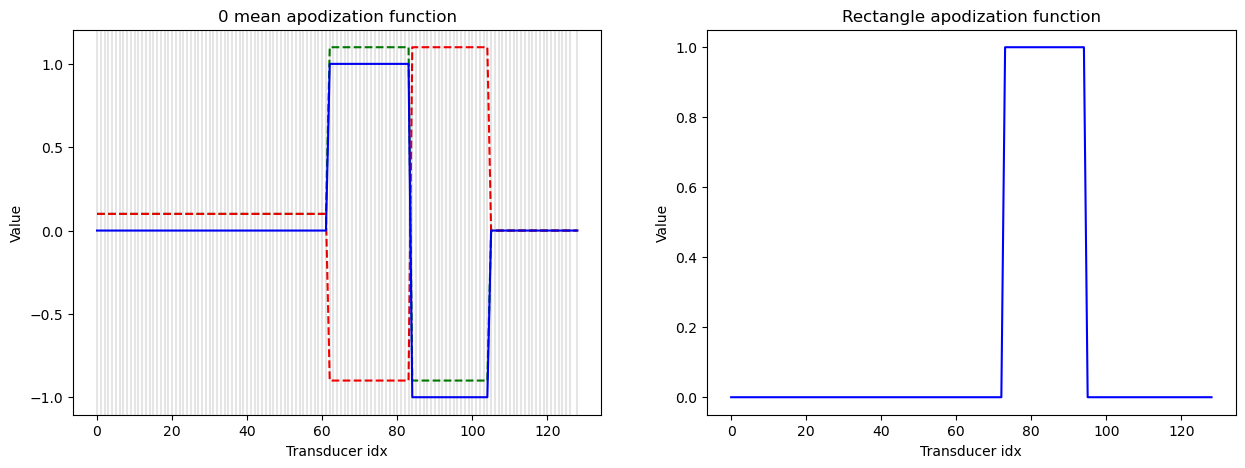

In [187]:
apodization_zm = generate_zm_apodization(objects, params["array"]["length"], offset=0, mirror=False)[:,1]
apodization_dc1 = generate_zm_apodization(objects, params["array"]["length"],  offset=0.1, mirror=False)[:,1]
apodization_dc2 = generate_zm_apodization(objects, params["array"]["length"],  offset=0.1, mirror=True)[:,1]
apodization_rectangle = generate_rectangle_apodization(objects, params["array"]["length"], 0.5, params["array"]["pitch"],offset=0)[:,1]

fig, ax = plt.subplots(1,2, figsize=(15, 5))

ax[0].plot(pos, apodization_dc1, color='g', ls='--')
ax[0].plot(pos, apodization_dc2, color='r', ls='--')
ax[0].plot(pos, apodization_zm, color='b')
for x in pos:
    ax[0].axvline(x=x, color='black', ls='-', alpha=0.1)
ax[0].set_title('0 mean apodization function')
ax[0].set_xlabel('Transducer idx')
ax[0].set_ylabel('Value')

ax[1].plot(pos, apodization_rectangle, color='b')
ax[1].set_title('Rectangle apodization function')
ax[1].set_xlabel('Transducer idx')
ax[1].set_ylabel('Value')
plt.show()

## Applying apodization (NSI)

In [188]:
def is_in_transducer_range(current_object : Objects, current_transducer, pitch):
    if current_transducer * pitch <= current_object.position - current_object.effective_array_length / 2 or current_transducer * pitch >= current_object.position + current_object.effective_array_length / 2:
        return 0
    else:
        return 1

In [189]:
def get_rf_matrices(objects : Objects, samples, array_length, pitch, angles, apodization_functions):
    rf_matrices_apodized = np.zeros((samples, array_length, len(angles), len(apodization_functions)))

    for h, apodization_values in enumerate(apodization_functions.items()):
        key = apodization_values[0]
        apodization_function = apodization_values[1]
        print(f"Generating RF matrices for {key} apodization function")
        for i in range(0, len(angles)):
            for j in range(0, len(objects)):
                for k in range(array_length):
                    #for each transducer, generate the wave with the corresponding delay
                    objects[j].rf_matrices[key][:,k,i] *= is_in_transducer_range(objects[j], k, pitch) * apodization_function[k,j]
                    
                rf_matrices_apodized[:, :, i, h] += objects[j].rf_matrices[key][:,:,i]
    
    return rf_matrices_apodized

In [190]:
apodization_functions = {
    "zm": generate_zm_apodization(objects, params["array"]["length"], offset=0, mirror=False),
    "dc1": generate_zm_apodization(objects, params["array"]["length"],  offset=0.1, mirror=False),
    "dc2": generate_zm_apodization(objects, params["array"]["length"],  offset=0.1, mirror=True),
    "rectangle": generate_rectangle_apodization(objects, params["array"]["length"], 0.5, params["array"]["pitch"],offset=0)
}

In [191]:
rf_apodized_summed_matrices = get_rf_matrices(
    objects, 
    samples, 
    params["array"]["length"], 
    params["array"]["pitch"], 
    params["wave"]["angles"], 
    apodization_functions
    )

Generating RF matrices for zm apodization function
Generating RF matrices for dc1 apodization function
Generating RF matrices for dc2 apodization function
Generating RF matrices for rectangle apodization function


## Visualize summed RF matrices 

### ZM

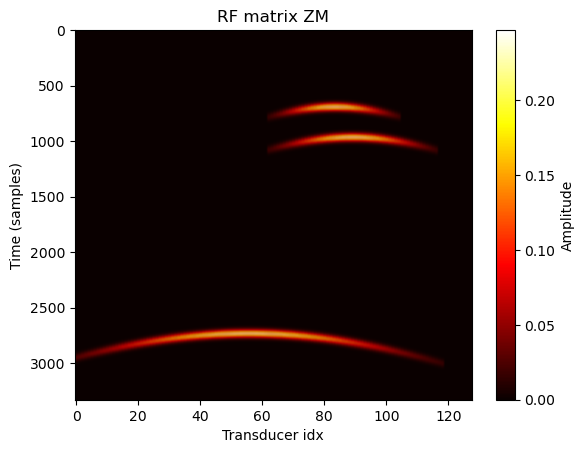

In [192]:
plt.imshow(abs(rf_apodized_summed_matrices[:,:,0,0]), cmap='hot', aspect='auto')
plt.xlabel("Transducer idx")
plt.ylabel("Time (samples)")
plt.colorbar(label="Amplitude")
plt.title("RF matrix ZM")
plt.savefig("./data_nsi/images/rf_matrix_zm.png")
plt.show()

### DC1

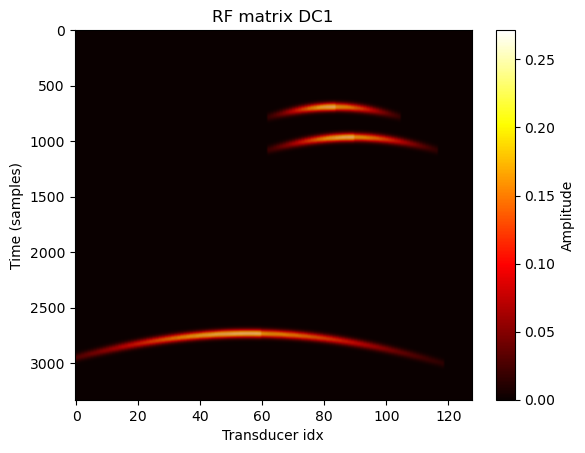

In [193]:
plt.imshow(abs(rf_apodized_summed_matrices[:,:,0,1]), cmap='hot', aspect='auto')
plt.xlabel("Transducer idx")
plt.ylabel("Time (samples)")
plt.colorbar(label="Amplitude")
plt.title("RF matrix DC1")
plt.savefig("./data_nsi/images/rf_matrix_dc1.png")
plt.show()

### DC2

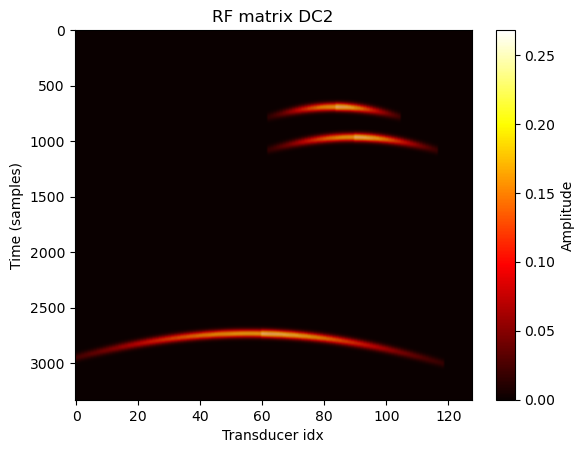

In [194]:
plt.imshow(abs(rf_apodized_summed_matrices[:,:,0,2]), cmap='hot', aspect='auto')
plt.xlabel("Transducer idx")
plt.ylabel("Time (samples)")
plt.colorbar(label="Amplitude")
plt.title("RF matrix DC2")
plt.savefig("./data_nsi/images/rf_matrix_dc2.png")
plt.show()

### Rectangle

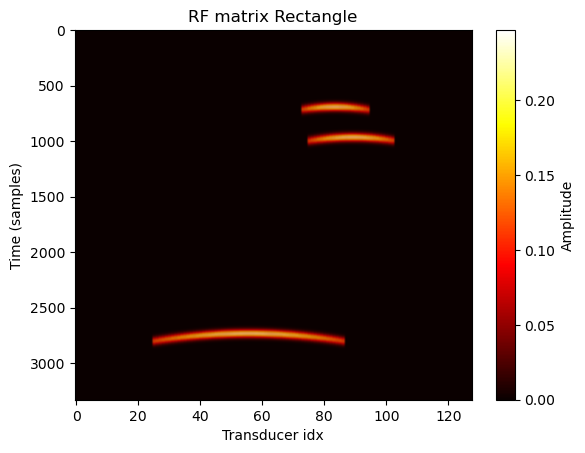

In [195]:
plt.imshow(abs(rf_apodized_summed_matrices[:,:,0,3]), cmap='hot', aspect='auto')
plt.xlabel("Transducer idx")
plt.ylabel("Time (samples)")
plt.colorbar(label="Amplitude")
plt.title("RF matrix Rectangle")
plt.savefig("./data_nsi/images/rf_matrix_rectangle.png")
plt.show()

# Beamforming

In [196]:
def save_beamformed_data(bf_matrix, filename, destination="./data_nsi/csv/beamformed/"):
    np.save(f"{destination}{filename}", bf_matrix)
    print("Beamformed data saved")

In [197]:
@njit(parallel=True)
def beamforming_opt(rf_summed_matrices, lateral_resolution, samples, total_depth, pitch, c, array_length, sampling_rate, angles = [0]):
    nb_apodization_functions = rf_summed_matrices.shape[3]
    bf_matrices = np.zeros((samples, lateral_resolution, len(angles), nb_apodization_functions))
    depth_step = (total_depth / 2) / samples #total depth in m / number of samples = depth per sample


    for h in range(0, nb_apodization_functions): #for each apodization function

        print("Beamforming for apodization function", h)
    
        for i in range(0, len(angles)): #for each angle

            print("   Beamforming for angle", angles[i], '°')

            for j in range(0, lateral_resolution): #for each lateral res sample

                for k in range(0, samples): #for vertical res sample

                    depth = depth_step*k
                    position = (pitch * array_length) * (j / lateral_resolution) #pitch isnt the same as the distance between transducers
                    # we normalize the index to the total array length

                    for l in range(0, array_length): #for each transducer

                        delay = ((depth * np.cos(angles[i] * np.pi/180) + position * np.sin(angles[i] * np.pi/180)) / c)  + (np.sqrt(depth**2 + (l * pitch - position)**2) / c)
                        delay_idx = int(delay * sampling_rate) #delay in s * sampling rate in 1/s = delay in samples (number of samples to reach delay)

                        if delay_idx < samples:
                            bf_matrices[k,j,i,h] += rf_summed_matrices[delay_idx, l, i, h] #we take sample in calculated rf_matrix (faster than recalculating)
            
    return bf_matrices

In [198]:
bf_apodized_matrices = beamforming_opt(
    rf_apodized_summed_matrices, 
    params["simulation"]["lateral_resolution"], 
    samples, 
    params["simulation"]["total_depth"], 
    params["array"]["pitch"], 
    params["wave"]["c"], 
    params["array"]["length"], 
    sampling_rate, 
    params["wave"]["angles"]
)

save_beamformed_data(bf_apodized_matrices, beamformed_apodized_matrix_name, destination="./data_nsi/csv/beamformed_apodizations/")

Beamforming for apodization function 0
   Beamforming for angle -15.0 °
   Beamforming for angle -14.0 °
   Beamforming for angle -13.0 °
   Beamforming for angle -12.0 °
   Beamforming for angle -11.0 °
   Beamforming for angle -10.0 °
   Beamforming for angle -9.0 °
   Beamforming for angle -8.0 °
   Beamforming for angle -7.0 °
   Beamforming for angle -6.0 °
   Beamforming for angle -5.0 °
   Beamforming for angle -4.0 °
   Beamforming for angle -3.0 °
   Beamforming for angle -2.0 °
   Beamforming for angle -1.0 °
   Beamforming for angle 0.0 °
   Beamforming for angle 1.0 °
   Beamforming for angle 2.0 °
   Beamforming for angle 3.0 °
   Beamforming for angle 4.0 °
   Beamforming for angle 5.0 °
   Beamforming for angle 6.0 °
   Beamforming for angle 7.0 °
   Beamforming for angle 8.0 °
   Beamforming for angle 9.0 °
   Beamforming for angle 10.0 °
   Beamforming for angle 11.0 °
   Beamforming for angle 12.0 °
   Beamforming for angle 13.0 °
   Beamforming for angle 14.0 °
   Be

In [199]:
bf_apodized_matrices_loaded = np.load(f"./data_nsi/csv/beamformed_apodizations/{beamformed_apodized_matrix_name}.npy")

In [200]:
bf_apodized_matrices_summed = np.sum(bf_apodized_matrices_loaded, axis=2)

## Envelopes

In [201]:
def get_envelope(bf_matrix, samples, lateral_resolution):
    env = np.zeros((samples, lateral_resolution))
    for i in range(0, lateral_resolution):
        env[:, i] = envelope(bf_matrix[:, i], residual=None)
    return env

In [202]:
bf_matrix_zm = bf_apodized_matrices_summed[:,:,0]
bf_matrix_dc1 = bf_apodized_matrices_summed[:,:,1]
bf_matrix_dc2 = bf_apodized_matrices_summed[:,:,2]
bf_matrix_rectangle = bf_apodized_matrices_summed[:,:,3]

env_zm = get_envelope(bf_matrix_zm, samples, params["simulation"]["lateral_resolution"])
env_dc1 = get_envelope(bf_matrix_dc1, samples, params["simulation"]["lateral_resolution"])
env_dc2 = get_envelope(bf_matrix_dc2, samples, params["simulation"]["lateral_resolution"])

## Average offsets and sum

In [203]:
env_nsi = (env_dc1 + env_dc2) / 2 - env_zm
save_beamformed_data(env_nsi, f"{beamformed_apodized_matrix_name}_env_nsi")
save_beamformed_data(bf_matrix_rectangle, f"{beamformed_apodized_matrix_name}_rectangle")

Beamformed data saved
Beamformed data saved
